 自适应源点 KM-PIKFNN：含光滑非规则孔的有限方板

 本算例直接在物理平面定义非规则孔，不使用保角映射。KM 点力基本解解析满足
 无体力二维各向同性弹性控制方程，线性核系数通过最小二乘求解；小型神经网络
 只学习孔内虚拟源点的空间变化位置 alpha(theta)。

运行前请准备 COMSOL 导出的 `irregular_hole_M1/M2/M3_grid_801.txt`。
程序先检查 M1->M2->M3 的网格收敛性，再固定使用 M3 作为最终参考解。


In [1]:
from __future__ import annotations

import copy
import csv
import math
import os
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn


os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(42)

# ------------------------- physical parameters -------------------------
DTYPE = torch.float64
# Float64 is normally more stable on CPU. Set KM_DEVICE=cuda manually if desired.
DEVICE = torch.device(os.environ.get("KM_DEVICE", "cpu"))

L_REAL = 1.0                 # half width of square plate, m
R0_REAL = 0.42               # mean hole radius, m
EPS3 = 0.22
EPS5 = 0.08
E_REAL = 1000.0              # Pa
NU = 0.30
U0_REAL = 1.0e-3             # m

# x*=x/L, u*=u/U0, sigma*=sigma/(E U0/L)
R0 = R0_REAL / L_REAL
E_STAR = 1.0
G_STAR = E_STAR / (2.0 * (1.0 + NU))
KAPPA = (3.0 - NU) / (1.0 + NU)       # plane stress
SIGMA_SCALE = E_REAL * U0_REAL / L_REAL

# ------------------------- numerical configuration ---------------------
N_HOLE_SOURCES = 32
N_OUTER_SOURCES_PER_SIDE = 18
N_HOLE_BND = 480
N_SIDE_BND = 140
OUTER_SOURCE_OFFSET = 0.25

ALPHA_MIN = 0.20
ALPHA_MAX = 0.92
FIXED_DEFAULT_ALPHA = 0.65
FIXED_ALPHA_GRID = np.arange(0.30, 0.901, 0.05)

RCOND = 1.0e-11
W_HOLE = 3.0
W_DISP = 10.0
W_TRACTION = 1.0
W_ANCHOR = 1.0

FAST_DEMO = os.environ.get("KM_FAST_DEMO", "0") == "1"
ADAPT_CYCLES = 3 if FAST_DEMO else 14
SOURCE_STEPS_PER_CYCLE = 10 if FAST_DEMO else 80
SOURCE_LR = 3.0e-3
REG_SMOOTH = 2.0e-4
REG_MOVE = 2.0e-6

# ------------------------- FEM reference checks ------------------------
# These are screening tolerances, not a replacement for reporting the actual
# M1-M2 and M2-M3 differences in the paper.
NEAR_HOLE_RADIUS = 0.80
FEM_TOL_DISP_GLOBAL = 5.0e-4
FEM_TOL_STRESS_GLOBAL = 2.0e-3
FEM_TOL_STRESS_NEAR = 5.0e-3

COMSOL_M1_FILE = Path(
    r"C:\Users\magic\Desktop\KM-PIKFNN\不规则圆孔\irregular_hole_M1_grid_801.txt"
)

COMSOL_M2_FILE = Path(
    r"C:\Users\magic\Desktop\KM-PIKFNN\不规则圆孔\irregular_hole_M2_grid_801.txt"
)

COMSOL_M3_FILE = Path(
    r"C:\Users\magic\Desktop\KM-PIKFNN\不规则圆孔\irregular_hole_M3_grid_801.txt"
)

for name, path in {
    "M1": COMSOL_M1_FILE,
    "M2": COMSOL_M2_FILE,
    "M3": COMSOL_M3_FILE,
}.items():
    print(f"{name}: {path}")
    print(f"    exists = {path.is_file()}")
    assert path.is_file(), f"找不到{name}文件：{path}"

# 最终参考解
COMSOL_FILE = COMSOL_M3_FILE
OUTPUT_DIR = Path("irregular_hole_km_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=== Adaptive-source KM-PIKFNN for an irregular cavity ===")
print(f"device={DEVICE}, dtype={DTYPE}, plane-stress kappa={KAPPA:.8f}")
print(f"E*={E_STAR:.1f}, G*={G_STAR:.8f}, stress scale={SIGMA_SCALE:g} Pa")
print(f"fast demo={FAST_DEMO}")


M1: C:\Users\magic\Desktop\KM-PIKFNN\不规则圆孔\irregular_hole_M1_grid_801.txt
    exists = True
M2: C:\Users\magic\Desktop\KM-PIKFNN\不规则圆孔\irregular_hole_M2_grid_801.txt
    exists = True
M3: C:\Users\magic\Desktop\KM-PIKFNN\不规则圆孔\irregular_hole_M3_grid_801.txt
    exists = True
=== Adaptive-source KM-PIKFNN for an irregular cavity ===
device=cpu, dtype=torch.float64, plane-stress kappa=2.07692308
E*=1.0, G*=0.38461538, stress scale=1 Pa
fast demo=False


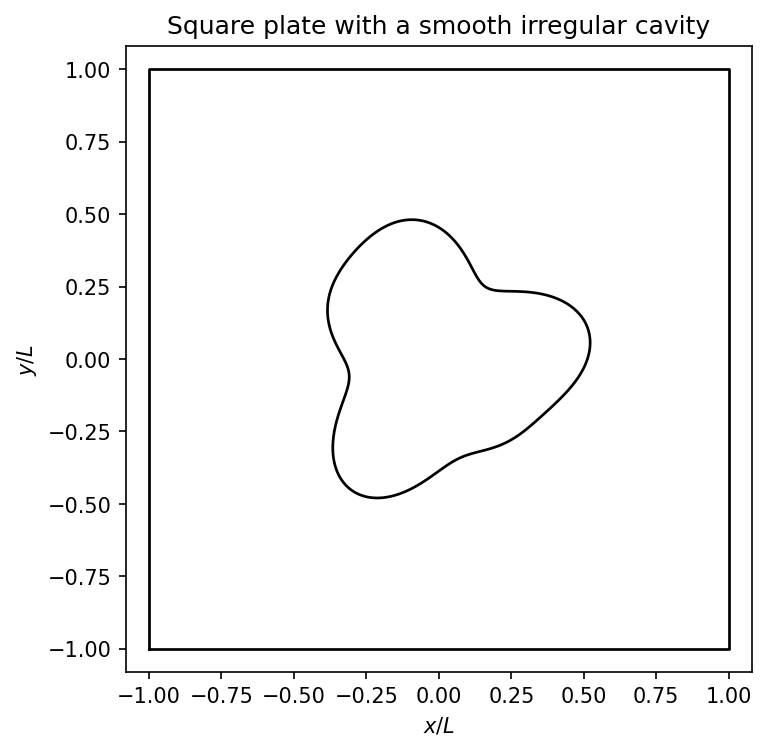

In [2]:
def hole_radius(theta):
    return R0 * (1.0 + EPS3 * np.cos(3.0 * theta) + EPS5 * np.sin(5.0 * theta))


def hole_radius_derivatives(theta):
    r = hole_radius(theta)
    rp = R0 * (-3.0 * EPS3 * np.sin(3.0 * theta) + 5.0 * EPS5 * np.cos(5.0 * theta))
    rpp = R0 * (-9.0 * EPS3 * np.cos(3.0 * theta) - 25.0 * EPS5 * np.sin(5.0 * theta))
    return r, rp, rpp


def hole_curve(theta):
    r = hole_radius(theta)
    return np.column_stack((r * np.cos(theta), r * np.sin(theta)))


def hole_geometry(theta):
    """Boundary points, physical-domain outward normals, arc weights, curvature."""
    r, rp, rpp = hole_radius_derivatives(theta)
    c, s = np.cos(theta), np.sin(theta)
    x = r * c
    y = r * s
    xp = rp * c - r * s
    yp = rp * s + r * c
    xpp = rpp * c - 2.0 * rp * s - r * c
    ypp = rpp * s + 2.0 * rp * c - r * s
    ds = np.sqrt(xp**2 + yp**2)
    # CCW hole curve: outward normal of the material domain points into the hole.
    nx = -yp / ds
    ny = xp / ds
    curvature = np.abs(xp * ypp - yp * xpp) / np.maximum(ds**3, 1.0e-15)
    return np.column_stack((x, y)), np.column_stack((nx, ny)), ds, curvature


def midpoint_parameter(n: int, phase: float) -> np.ndarray:
    return (np.arange(int(n), dtype=float) + phase) / float(n)


def make_boundary_data(n_hole=N_HOLE_BND, n_side=N_SIDE_BND, phase=0.5):
    theta = 2.0 * np.pi * midpoint_parameter(n_hole, phase)
    hole_xy, hole_n, hole_ds, _ = hole_geometry(theta)

    t = -1.0 + 2.0 * midpoint_parameter(n_side, phase)
    top = np.column_stack((t, np.ones_like(t)))
    bottom = np.column_stack((t, -np.ones_like(t)))
    right = np.column_stack((np.ones_like(t), t))
    left = np.column_stack((-np.ones_like(t), t))
    return {
        "theta": theta,
        "hole": hole_xy,
        "hole_n": hole_n,
        "hole_ds": hole_ds,
        "top": top,
        "bottom": bottom,
        "right": right,
        "left": left,
    }


def combine_boundary_data(first, second):
    combined = {}
    for key in ("theta", "hole", "hole_n", "hole_ds", "top", "bottom", "right", "left"):
        combined[key] = np.concatenate((first[key], second[key]), axis=0)
    return combined


TRAIN_DATA = make_boundary_data(phase=0.25)
VALID_DATA = make_boundary_data(phase=0.75)
COMBINED_DATA = combine_boundary_data(TRAIN_DATA, VALID_DATA)
TEST_DATA = make_boundary_data(n_hole=2 * N_HOLE_BND, n_side=2 * N_SIDE_BND, phase=0.50)


def discover_comsol_file() -> Path | None:
    if COMSOL_FILE is not None:
        path = Path(COMSOL_FILE)
        return path if path.exists() else None
    patterns = [
        "*M3*grid*801*.txt", "*M3*.txt",
        "*M2*grid*801*.txt", "*M2*.txt",
        "*M1*grid*801*.txt", "*M1*.txt",
    ]
    search_dirs = [Path.cwd(), Path.cwd() / "data"]
    for pattern in patterns:
        for directory in search_dirs:
            candidates = sorted(directory.glob(pattern)) if directory.exists() else []
            if candidates:
                return candidates[0]
    return None


def load_comsol_grid(path: Path):
    """Read x,y,u,v,sxx,syy,sxy,vm from a COMSOL spreadsheet text/CSV export."""
    first_data_line = ""
    with path.open("r", encoding="utf-8", errors="ignore") as stream:
        for line in stream:
            stripped = line.strip()
            if stripped and not stripped.startswith("%"):
                first_data_line = stripped
                break
    delimiter = "," if "," in first_data_line else None
    data = np.genfromtxt(path, comments="%", delimiter=delimiter, dtype=float)
    data = np.atleast_2d(data)
    data = data[~np.all(np.isnan(data), axis=1)]
    if data.shape[1] < 8:
        raise ValueError(
            f"COMSOL file has {data.shape[1]} columns; expected at least 8 in the order "
            "x,y,u,v,solid.sx,solid.sy,solid.sxy,solid.mises."
        )
    # COMSOL exports can occasionally use a different row order. Canonical
    # sorting guarantees pointwise M1/M2/M3 comparisons on the same grid.
    order = np.lexsort((data[:, 0], data[:, 1]))
    data = data[order]
    return {
        "x": data[:, 0], "y": data[:, 1],
        "ux": data[:, 2], "uy": data[:, 3],
        "sxx": data[:, 4], "syy": data[:, 5], "sxy": data[:, 6],
        "vm": data[:, 7], "raw": data,
    }


theta_plot = np.linspace(0.0, 2.0 * np.pi, 1000, endpoint=True)
hole_plot = hole_curve(theta_plot)
fig, ax = plt.subplots(figsize=(5.2, 5.2), dpi=150)
ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], "k-", lw=1.3)
ax.fill(hole_plot[:, 0], hole_plot[:, 1], color="white", ec="k", lw=1.3)
ax.set_aspect("equal")
ax.set_xlim(-1.08, 1.08)
ax.set_ylim(-1.08, 1.08)
ax.set_xlabel(r"$x/L$")
ax.set_ylabel(r"$y/L$")
ax.set_title("Square plate with a smooth irregular cavity")
plt.tight_layout()
plt.show()


In [3]:
def assert_matching_export_grid(first, second, first_name, second_name, atol=1.0e-12):
    """Fail early if two COMSOL exports are not sampled at identical coordinates."""
    if len(first["x"]) != len(second["x"]):
        raise ValueError(
            f"{first_name} and {second_name} contain different point counts: "
            f"{len(first['x'])} versus {len(second['x'])}. Export all meshes on the "
            "same 801 x 801 regular evaluation grid."
        )
    dx = np.nanmax(np.abs(first["x"] - second["x"]))
    dy = np.nanmax(np.abs(first["y"] - second["y"]))
    if not (dx <= atol and dy <= atol):
        raise ValueError(
            f"{first_name} and {second_name} do not use the same evaluation points "
            f"(max |dx|={dx:.3e}, max |dy|={dy:.3e}). Re-export them with identical "
            "x/y ranges and point counts."
        )


def joint_finite_mask(first, second, fields, spatial_mask):
    mask = np.asarray(spatial_mask, dtype=bool).copy()
    for key in fields:
        mask &= np.isfinite(first[key]) & np.isfinite(second[key])
    return mask


def paired_relative_l2(first, second, fields, spatial_mask, align_ux=False):
    """Relative L2 difference; `second` is the finer-mesh reference."""
    mask = joint_finite_mask(first, second, fields, spatial_mask)
    if not np.any(mask):
        return np.nan
    numerator = 0.0
    denominator = 0.0
    for key in fields:
        coarse = np.asarray(first[key][mask], dtype=float).copy()
        fine = np.asarray(second[key][mask], dtype=float).copy()
        if align_ux and key == "ux":
            # Remove only the arbitrary x rigid-translation difference.
            coarse -= np.mean(coarse - fine)
        numerator += float(np.dot(coarse - fine, coarse - fine))
        denominator += float(np.dot(fine, fine))
    return math.sqrt(numerator / max(denominator, 1.0e-30))


def fem_pair_metrics(coarse, fine):
    radius = np.hypot(fine["x"] / L_REAL, fine["y"] / L_REAL)
    regions = {
        "global": np.ones(len(radius), dtype=bool),
        "near_hole": radius <= NEAR_HOLE_RADIUS,
    }
    result = {}
    for region_name, region_mask in regions.items():
        values = {
            "u_vector": paired_relative_l2(
                coarse, fine, ("ux", "uy"), region_mask, align_ux=True
            ),
            "stress_tensor": paired_relative_l2(
                coarse, fine, ("sxx", "syy", "sxy"), region_mask
            ),
        }
        for key in ("ux", "uy", "sxx", "syy", "sxy", "vm"):
            values[key] = paired_relative_l2(
                coarse, fine, (key,), region_mask, align_ux=(key == "ux")
            )
        result[region_name] = values
    return result


def print_fem_convergence_table(m12, m23):
    print("\n=== COMSOL mesh-convergence check on the common 801 x 801 grid ===")
    print(
        f"{'Region':<13}{'Quantity':<16}{'M1 -> M2':>14}"
        f"{'M2 -> M3':>14}{'ratio':>11}"
    )
    for region in ("global", "near_hole"):
        for quantity in ("u_vector", "stress_tensor", "vm"):
            e12 = m12[region][quantity]
            e23 = m23[region][quantity]
            ratio = e23 / max(e12, 1.0e-30)
            print(f"{region:<13}{quantity:<16}{e12:>14.4e}{e23:>14.4e}{ratio:>11.3f}")


FEM_M1 = load_comsol_grid(COMSOL_M1_FILE)
FEM_M2 = load_comsol_grid(COMSOL_M2_FILE)
FEM_M3 = load_comsol_grid(COMSOL_M3_FILE)
assert_matching_export_grid(FEM_M1, FEM_M2, "M1", "M2")
assert_matching_export_grid(FEM_M2, FEM_M3, "M2", "M3")

FEM_CONV_M1_M2 = fem_pair_metrics(FEM_M1, FEM_M2)
FEM_CONV_M2_M3 = fem_pair_metrics(FEM_M2, FEM_M3)
print_fem_convergence_table(FEM_CONV_M1_M2, FEM_CONV_M2_M3)

FEM_MESH_CONVERGED = (
    FEM_CONV_M2_M3["global"]["u_vector"] <= FEM_TOL_DISP_GLOBAL
    and FEM_CONV_M2_M3["global"]["stress_tensor"] <= FEM_TOL_STRESS_GLOBAL
    and FEM_CONV_M2_M3["near_hole"]["stress_tensor"] <= FEM_TOL_STRESS_NEAR
    and FEM_CONV_M2_M3["global"]["u_vector"] < FEM_CONV_M1_M2["global"]["u_vector"]
    and FEM_CONV_M2_M3["global"]["stress_tensor"] < FEM_CONV_M1_M2["global"]["stress_tensor"]
)
if FEM_MESH_CONVERGED:
    print("FEM reference status: PASS. M3 will be used as the final reference solution.")
else:
    print(
        "FEM reference status: WARNING. M3 will still be used, but the M2-M3 "
        "difference is not yet below all screening criteria. Refine further or "
        "report M3 as a provisional reference."
    )

fem_convergence_path = OUTPUT_DIR / "comsol_mesh_convergence.csv"
with fem_convergence_path.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow(["mesh_pair", "region", "quantity", "relative_l2"])
    for pair_name, metrics in (
        ("M1-M2", FEM_CONV_M1_M2),
        ("M2-M3", FEM_CONV_M2_M3),
    ):
        for region in ("global", "near_hole"):
            for quantity in ("u_vector", "ux", "uy", "stress_tensor", "sxx", "syy", "sxy", "vm"):
                writer.writerow([pair_name, region, quantity, metrics[region][quantity]])
print(f"Mesh-convergence data saved to: {fem_convergence_path}")



=== COMSOL mesh-convergence check on the common 801 x 801 grid ===
Region       Quantity              M1 -> M2      M2 -> M3      ratio
global       u_vector            2.2726e-04    2.6084e-05      0.115
global       stress_tensor       1.0344e-02    2.9254e-03      0.283
global       vm                  7.8234e-03    2.1555e-03      0.276
near_hole    u_vector            3.0345e-04    3.5284e-05      0.116
near_hole    stress_tensor       1.4985e-02    4.2727e-03      0.285
near_hole    vm                  1.1478e-02    3.1789e-03      0.277
FEM reference status: WARNING. M3 will still be used, but the M2-M3 difference is not yet below all screening criteria. Refine further or report M3 as a provisional reference.
Mesh-convergence data saved to: irregular_hole_km_outputs\comsol_mesh_convergence.csv


In [4]:
def outer_source_points(n_per_side=N_OUTER_SOURCES_PER_SIDE, offset=OUTER_SOURCE_OFFSET):
    t = -1.0 + 2.0 * midpoint_parameter(n_per_side, 0.5)
    bottom = np.column_stack((t, -(1.0 + offset) * np.ones_like(t)))
    right = np.column_stack(((1.0 + offset) * np.ones_like(t), t))
    top = np.column_stack((t[::-1], (1.0 + offset) * np.ones_like(t)))
    left = np.column_stack((-(1.0 + offset) * np.ones_like(t), t[::-1]))
    return np.vstack((bottom, right, top, left))


SOURCE_THETA = 2.0 * np.pi * midpoint_parameter(N_HOLE_SOURCES, 0.5)
SOURCE_RADIUS = hole_radius(SOURCE_THETA)
OUTER_SOURCES = outer_source_points()


def fixed_source_points(alpha: float) -> np.ndarray:
    hole_sources = np.column_stack((
        alpha * SOURCE_RADIUS * np.cos(SOURCE_THETA),
        alpha * SOURCE_RADIUS * np.sin(SOURCE_THETA),
    ))
    return np.vstack((hole_sources, OUTER_SOURCES))


def coefficient_count(n_sources: int) -> int:
    return 2 * int(n_sources) + 8


def unpack_coefficients(coeffs, n_sources):
    coeffs = np.asarray(coeffs, dtype=float)
    force = coeffs[:n_sources] + 1j * coeffs[n_sources:2 * n_sources]
    i = 2 * n_sources
    phi0 = coeffs[i] + 1j * coeffs[i + 1]
    phi1 = coeffs[i + 2] + 1j * coeffs[i + 3]
    psi0 = coeffs[i + 4] + 1j * coeffs[i + 5]
    psi1 = coeffs[i + 6] + 1j * coeffs[i + 7]
    return force, phi0, phi1, psi0, psi1


def fields_from_coefficients_np(points, sources, coeffs):
    points = np.asarray(points, dtype=float)
    sources = np.asarray(sources, dtype=float)
    z = points[:, 0] + 1j * points[:, 1]
    zeta = sources[:, 0] + 1j * sources[:, 1]
    q = z[:, None] - zeta[None, :]
    logq = np.log(np.maximum(np.abs(q), 1.0e-300)) + 1j * np.angle(q)
    d1 = 1.0 / q
    d2 = -1.0 / q**2
    force, phi0, phi1, psi0, psi1 = unpack_coefficients(coeffs, len(sources))
    cf = 1.0 / (2.0 * np.pi * (KAPPA + 1.0))
    phi = -cf * (logq @ force) + phi0 + phi1 * z
    dphi = -cf * (d1 @ force) + phi1
    d2phi = -cf * (d2 @ force)
    psi = cf * (KAPPA * (logq @ np.conj(force)) + (d1 * np.conj(zeta)[None, :]) @ force) + psi0 + psi1 * z
    dpsi = cf * (KAPPA * (d1 @ np.conj(force)) + (d2 * np.conj(zeta)[None, :]) @ force) + psi1
    disp = (KAPPA * phi - z * np.conj(dphi) - np.conj(psi)) / (2.0 * G_STAR)
    stress_sum = 4.0 * dphi.real
    stress_diff = 2.0 * (np.conj(z) * d2phi + dpsi)
    sxx = 0.5 * (stress_sum - stress_diff.real)
    syy = 0.5 * (stress_sum + stress_diff.real)
    sxy = 0.5 * stress_diff.imag
    return disp.real, disp.imag, sxx, syy, sxy


def _components_from_response(z, phi, dphi, d2phi, psi, dpsi):
    disp = (KAPPA * phi - z[:, None] * np.conj(dphi) - np.conj(psi)) / (2.0 * G_STAR)
    stress_sum = 4.0 * dphi.real
    stress_diff = 2.0 * (np.conj(z)[:, None] * d2phi + dpsi)
    return {
        "ux": disp.real,
        "uy": disp.imag,
        "sxx": 0.5 * (stress_sum - stress_diff.real),
        "syy": 0.5 * (stress_sum + stress_diff.real),
        "sxy": 0.5 * stress_diff.imag,
    }


def field_design_matrices_np(points, sources):
    """Matrices mapping real KM coefficients to the five physical fields."""
    points = np.asarray(points, dtype=float)
    sources = np.asarray(sources, dtype=float)
    z = points[:, 0] + 1j * points[:, 1]
    zeta = sources[:, 0] + 1j * sources[:, 1]
    q = z[:, None] - zeta[None, :]
    logq = np.log(np.maximum(np.abs(q), 1.0e-300)) + 1j * np.angle(q)
    d1 = 1.0 / q
    d2 = -1.0 / q**2
    zb = np.conj(zeta)[None, :]
    cf = 1.0 / (2.0 * np.pi * (KAPPA + 1.0))

    # Unit real point-force coefficients.
    phi_r = -cf * logq
    dphi_r = -cf * d1
    d2phi_r = -cf * d2
    psi_r = cf * (KAPPA * logq + d1 * zb)
    dpsi_r = cf * (KAPPA * d1 + d2 * zb)
    real_resp = _components_from_response(z, phi_r, dphi_r, d2phi_r, psi_r, dpsi_r)

    # Unit imaginary point-force coefficients. The conjugated-force term changes sign.
    phi_i = 1j * phi_r
    dphi_i = 1j * dphi_r
    d2phi_i = 1j * d2phi_r
    psi_i = 1j * cf * (-KAPPA * logq + d1 * zb)
    dpsi_i = 1j * cf * (-KAPPA * d1 + d2 * zb)
    imag_resp = _components_from_response(z, phi_i, dphi_i, d2phi_i, psi_i, dpsi_i)

    # Eight affine columns: Re/Im(phi0), Re/Im(phi1), Re/Im(psi0), Re/Im(psi1).
    p = len(z)
    phi = np.zeros((p, 8), dtype=complex)
    dphi = np.zeros_like(phi)
    d2phi = np.zeros_like(phi)
    psi = np.zeros_like(phi)
    dpsi = np.zeros_like(phi)
    phi[:, 0], phi[:, 1] = 1.0, 1j
    phi[:, 2], phi[:, 3] = z, 1j * z
    dphi[:, 2], dphi[:, 3] = 1.0, 1j
    psi[:, 4], psi[:, 5] = 1.0, 1j
    psi[:, 6], psi[:, 7] = z, 1j * z
    dpsi[:, 6], dpsi[:, 7] = 1.0, 1j
    affine_resp = _components_from_response(z, phi, dphi, d2phi, psi, dpsi)

    matrices = {}
    for key in real_resp:
        matrices[key] = np.concatenate((real_resp[key], imag_resp[key], affine_resp[key]), axis=1)
    return matrices


def assemble_boundary_system(sources, data):
    rows, targets = [], []

    def add_group(matrix, target, weight, sample_weight=None):
        target = np.broadcast_to(np.asarray(target, dtype=float), (matrix.shape[0],))
        if sample_weight is None:
            normalized_weight = np.ones(matrix.shape[0], dtype=float)
        else:
            normalized_weight = np.asarray(sample_weight, dtype=float)
            normalized_weight = normalized_weight / np.mean(normalized_weight)
        scale = np.sqrt(weight * normalized_weight / max(matrix.shape[0], 1))
        rows.append(scale[:, None] * matrix)
        targets.append(scale * target)

    hole = field_design_matrices_np(data["hole"], sources)
    nx, ny = data["hole_n"][:, 0:1], data["hole_n"][:, 1:2]
    tx = nx * hole["sxx"] + ny * hole["sxy"]
    ty = nx * hole["sxy"] + ny * hole["syy"]
    add_group(tx, 0.0, W_HOLE, data["hole_ds"])
    add_group(ty, 0.0, W_HOLE, data["hole_ds"])

    outer_mats = {}
    for name in ("top", "bottom", "right", "left"):
        outer_mats[name] = field_design_matrices_np(data[name], sources)

    add_group(outer_mats["top"]["uy"], +1.0, W_DISP)
    add_group(outer_mats["top"]["sxy"], 0.0, W_TRACTION)
    add_group(outer_mats["bottom"]["uy"], -1.0, W_DISP)
    add_group(outer_mats["bottom"]["sxy"], 0.0, W_TRACTION)
    add_group(outer_mats["right"]["sxx"], 0.0, W_TRACTION)
    add_group(outer_mats["right"]["sxy"], 0.0, W_TRACTION)
    add_group(outer_mats["left"]["sxx"], 0.0, W_TRACTION)
    add_group(outer_mats["left"]["sxy"], 0.0, W_TRACTION)

    # Gauge condition equivalent to mean(ux)=0 on the outer boundary.
    outer_ux = np.vstack([outer_mats[name]["ux"] for name in ("top", "bottom", "right", "left")])
    add_group(np.mean(outer_ux, axis=0, keepdims=True), 0.0, W_ANCHOR)
    return np.vstack(rows), np.concatenate(targets)


def solve_linear_coefficients(sources, data, progress=False):
    tic = time.time()
    A, b = assemble_boundary_system(sources, data)
    coeffs, _, rank, singular_values = np.linalg.lstsq(A, b, rcond=RCOND)
    residual = A @ coeffs - b
    cond_raw = np.inf
    cond = np.inf
    if singular_values.size and singular_values[-1] > 0.0:
        cond_raw = singular_values[0] / singular_values[-1]
    if singular_values.size:
        retained = singular_values[singular_values > RCOND * singular_values[0]]
        if retained.size:
            cond = singular_values[0] / retained[-1]
    info = {
        "rows": int(A.shape[0]),
        "unknowns": int(A.shape[1]),
        "rank": int(rank),
        "loss": float(np.dot(residual, residual)),
        "rms": float(np.sqrt(np.mean(residual**2))),
        "max": float(np.max(np.abs(residual))),
        "condition": float(cond),
        "condition_raw": float(cond_raw),
        "coefficient_norm": float(np.linalg.norm(coeffs)),
        "time_s": float(time.time() - tic),
    }
    if progress:
        print(info)
    return coeffs, info


def boundary_loss_np(sources, coeffs, data):
    A, b = assemble_boundary_system(sources, data)
    residual = A @ coeffs - b
    return float(np.dot(residual, residual))



--- Fixed-source alpha sweep ---
alpha=0.30 | train=9.531e-02 | validation=9.530e-02 | cond=2.508e+09
alpha=0.35 | train=9.472e-02 | validation=9.472e-02 | cond=1.670e+08
alpha=0.40 | train=9.370e-02 | validation=9.369e-02 | cond=1.786e+07
alpha=0.45 | train=9.310e-02 | validation=9.310e-02 | cond=2.215e+06
alpha=0.50 | train=9.392e-02 | validation=9.392e-02 | cond=3.481e+05
alpha=0.55 | train=9.545e-02 | validation=9.545e-02 | cond=6.875e+04
alpha=0.60 | train=9.726e-02 | validation=9.726e-02 | cond=1.547e+04
alpha=0.65 | train=9.922e-02 | validation=9.921e-02 | cond=1.454e+04
alpha=0.70 | train=1.000e-01 | validation=1.000e-01 | cond=1.454e+04
alpha=0.75 | train=1.007e-01 | validation=1.007e-01 | cond=1.454e+04
alpha=0.80 | train=1.135e-01 | validation=1.135e-01 | cond=1.454e+04
alpha=0.85 | train=1.769e-01 | validation=1.769e-01 | cond=1.454e+04
alpha=0.90 | train=3.191e-01 | validation=3.191e-01 | cond=1.454e+04

Best fixed alpha selected without COMSOL data: 0.450
Best fixed refi

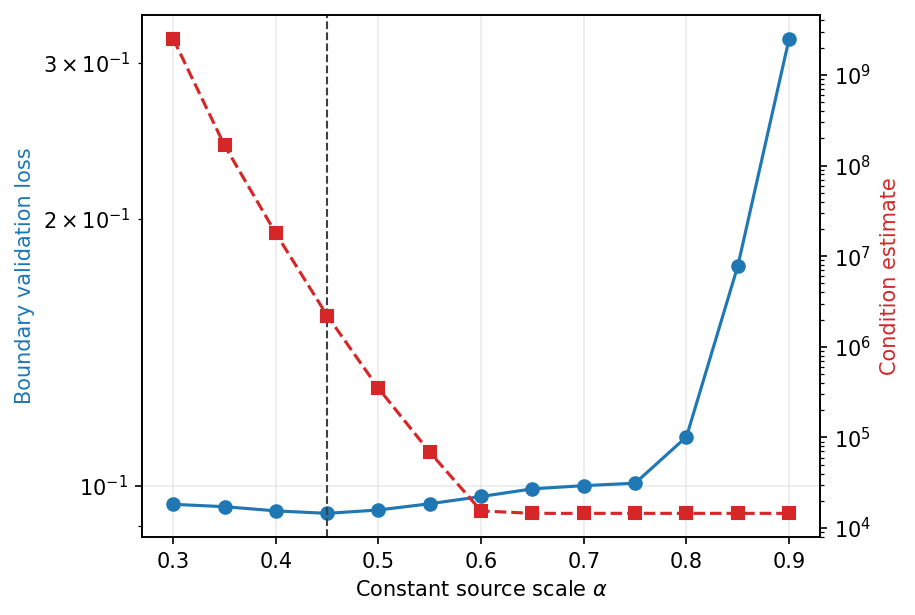

In [5]:
fixed_scan = []
print("\n--- Fixed-source alpha sweep ---")
for alpha in FIXED_ALPHA_GRID:
    sources = fixed_source_points(float(alpha))
    coeffs, train_info = solve_linear_coefficients(sources, TRAIN_DATA)
    val_loss = boundary_loss_np(sources, coeffs, VALID_DATA)
    fixed_scan.append({
        "alpha": float(alpha),
        "train_loss": train_info["loss"],
        "validation_loss": val_loss,
        "condition": train_info["condition"],
        "rank": train_info["rank"],
    })
    print(
        f"alpha={alpha:.2f} | train={train_info['loss']:.3e} | "
        f"validation={val_loss:.3e} | cond={train_info['condition']:.3e}"
    )

best_scan = min(fixed_scan, key=lambda item: item["validation_loss"])
BEST_FIXED_ALPHA = best_scan["alpha"]
FIXED_BEST_SOURCES = fixed_source_points(BEST_FIXED_ALPHA)
FIXED_BEST_COEFFS, FIXED_BEST_INFO = solve_linear_coefficients(FIXED_BEST_SOURCES, COMBINED_DATA)

FIXED_DEFAULT_SOURCES = fixed_source_points(FIXED_DEFAULT_ALPHA)
FIXED_DEFAULT_COEFFS, FIXED_DEFAULT_INFO = solve_linear_coefficients(FIXED_DEFAULT_SOURCES, COMBINED_DATA)

print(f"\nBest fixed alpha selected without COMSOL data: {BEST_FIXED_ALPHA:.3f}")
print("Best fixed refit:", FIXED_BEST_INFO)

scan_alpha = np.array([item["alpha"] for item in fixed_scan])
scan_val = np.array([item["validation_loss"] for item in fixed_scan])
scan_cond = np.array([item["condition"] for item in fixed_scan])
fig, ax1 = plt.subplots(figsize=(6.2, 4.2), dpi=150)
ax1.semilogy(scan_alpha, scan_val, "o-", color="#1f77b4", label="Validation loss")
ax1.axvline(BEST_FIXED_ALPHA, color="0.25", ls="--", lw=1.0)
ax1.set_xlabel(r"Constant source scale $\alpha$")
ax1.set_ylabel("Boundary validation loss", color="#1f77b4")
ax2 = ax1.twinx()
ax2.semilogy(scan_alpha, scan_cond, "s--", color="#d62728", label="Condition estimate")
ax2.set_ylabel("Condition estimate", color="#d62728")
ax1.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [6]:
def to_tensor(array):
    return torch.as_tensor(array, dtype=DTYPE, device=DEVICE)


def numpy_boundary_to_torch(data):
    return {key: to_tensor(value) for key, value in data.items()}


TRAIN_TORCH = numpy_boundary_to_torch(TRAIN_DATA)


class SourcePlacementNet(nn.Module):
    def __init__(self, initial_alpha: float, hidden: int = 12):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(5, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )
        self.to(device=DEVICE, dtype=DTYPE)
        p = (initial_alpha - ALPHA_MIN) / (ALPHA_MAX - ALPHA_MIN)
        p = float(np.clip(p, 1.0e-5, 1.0 - 1.0e-5))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.constant_(self.net[-1].bias, math.log(p / (1.0 - p)))

    def forward(self, features):
        return ALPHA_MIN + (ALPHA_MAX - ALPHA_MIN) * torch.sigmoid(self.net(features).squeeze(-1))


class AdaptiveSourceKM(nn.Module):
    def __init__(self, initial_alpha=BEST_FIXED_ALPHA):
        super().__init__()
        _, _, _, curvature = hole_geometry(SOURCE_THETA)
        curvature_feature = (curvature - curvature.mean()) / max(curvature.std(), 1.0e-12)
        features = np.column_stack((
            np.cos(SOURCE_THETA), np.sin(SOURCE_THETA),
            np.cos(2.0 * SOURCE_THETA), np.sin(2.0 * SOURCE_THETA),
            curvature_feature,
        ))
        self.register_buffer("theta", to_tensor(SOURCE_THETA))
        self.register_buffer("radius", to_tensor(SOURCE_RADIUS))
        self.register_buffer("features", to_tensor(features))
        self.register_buffer("outer_sources", to_tensor(OUTER_SOURCES))
        self.source_net = SourcePlacementNet(initial_alpha)
        n_total = N_HOLE_SOURCES + len(OUTER_SOURCES)
        self.coeffs = nn.Parameter(torch.zeros(coefficient_count(n_total), dtype=DTYPE, device=DEVICE))
        self.initial_alpha = float(initial_alpha)

    def alpha(self):
        return self.source_net(self.features)

    def source_points(self):
        alpha = self.alpha()
        hole = torch.stack((
            alpha * self.radius * torch.cos(self.theta),
            alpha * self.radius * torch.sin(self.theta),
        ), dim=1)
        return torch.cat((hole, self.outer_sources), dim=0)

    def source_points_numpy(self):
        with torch.no_grad():
            return self.source_points().detach().cpu().numpy()

    def set_coefficients(self, coeffs):
        with torch.no_grad():
            self.coeffs.copy_(to_tensor(coeffs))

    def source_regularization(self):
        alpha = self.alpha()
        cyclic_diff = alpha - torch.roll(alpha, shifts=1)
        smooth = torch.mean(cyclic_diff.square()) / (ALPHA_MAX - ALPHA_MIN)**2
        move = torch.mean((alpha - self.initial_alpha)**2) / (ALPHA_MAX - ALPHA_MIN)**2
        return REG_SMOOTH * smooth + REG_MOVE * move

    def fields(self, points):
        points = points.to(device=DEVICE, dtype=DTYPE)
        sources = self.source_points()
        z = torch.complex(points[:, 0], points[:, 1])
        zeta = torch.complex(sources[:, 0], sources[:, 1])
        q = z[:, None] - zeta[None, :]
        logq = torch.log(torch.clamp(torch.abs(q), min=1.0e-30)) + 1j * torch.angle(q)
        d1 = 1.0 / q
        d2 = -1.0 / q.square()
        n_sources = len(zeta)
        c = self.coeffs
        force = torch.complex(c[:n_sources], c[n_sources:2 * n_sources])
        i = 2 * n_sources
        phi0 = torch.complex(c[i], c[i + 1])
        phi1 = torch.complex(c[i + 2], c[i + 3])
        psi0 = torch.complex(c[i + 4], c[i + 5])
        psi1 = torch.complex(c[i + 6], c[i + 7])
        cf = 1.0 / (2.0 * np.pi * (KAPPA + 1.0))
        phi = -cf * (logq @ force) + phi0 + phi1 * z
        dphi = -cf * (d1 @ force) + phi1
        d2phi = -cf * (d2 @ force)
        psi = cf * (KAPPA * (logq @ torch.conj(force)) + (d1 * torch.conj(zeta)[None, :]) @ force) + psi0 + psi1 * z
        dpsi = cf * (KAPPA * (d1 @ torch.conj(force)) + (d2 * torch.conj(zeta)[None, :]) @ force) + psi1
        disp = (KAPPA * phi - z * torch.conj(dphi) - torch.conj(psi)) / (2.0 * G_STAR)
        stress_sum = 4.0 * dphi.real
        stress_diff = 2.0 * (torch.conj(z) * d2phi + dpsi)
        return {
            "ux": disp.real,
            "uy": disp.imag,
            "sxx": 0.5 * (stress_sum - stress_diff.real),
            "syy": 0.5 * (stress_sum + stress_diff.real),
            "sxy": 0.5 * stress_diff.imag,
        }


def adaptive_boundary_loss(model, data):
    hole = model.fields(data["hole"])
    nx, ny = data["hole_n"][:, 0], data["hole_n"][:, 1]
    tx = nx * hole["sxx"] + ny * hole["sxy"]
    ty = nx * hole["sxy"] + ny * hole["syy"]
    hole_weight = data["hole_ds"] / torch.mean(data["hole_ds"])
    loss_hole = W_HOLE * (
        torch.mean(hole_weight * tx.square()) + torch.mean(hole_weight * ty.square())
    )

    top = model.fields(data["top"])
    bottom = model.fields(data["bottom"])
    right = model.fields(data["right"])
    left = model.fields(data["left"])
    loss_disp = W_DISP * (
        torch.mean((top["uy"] - 1.0).square()) +
        torch.mean((bottom["uy"] + 1.0).square())
    )
    loss_traction = W_TRACTION * (
        torch.mean(top["sxy"].square()) + torch.mean(bottom["sxy"].square()) +
        torch.mean(right["sxx"].square()) + torch.mean(right["sxy"].square()) +
        torch.mean(left["sxx"].square()) + torch.mean(left["sxy"].square())
    )
    mean_ux = torch.mean(torch.cat((top["ux"], bottom["ux"], right["ux"], left["ux"])))
    loss_anchor = W_ANCHOR * mean_ux.square()
    physics = loss_hole + loss_disp + loss_traction + loss_anchor
    regularization = model.source_regularization()
    return physics + regularization, {
        "physics": physics,
        "hole": loss_hole,
        "disp": loss_disp,
        "traction": loss_traction,
        "anchor": loss_anchor,
        "regularization": regularization,
    }


model = AdaptiveSourceKM(BEST_FIXED_ALPHA)
initial_sources = model.source_points_numpy().copy()
initial_coeffs, _ = solve_linear_coefficients(initial_sources, TRAIN_DATA)
model.set_coefficients(initial_coeffs)
model.coeffs.requires_grad_(False)

optimizer = torch.optim.Adam(model.source_net.parameters(), lr=SOURCE_LR)
training_history = []
best_state = copy.deepcopy(model.state_dict())
best_validation_loss = boundary_loss_np(initial_sources, initial_coeffs, VALID_DATA)

print("\n--- Adaptive source optimization ---")
for cycle in range(ADAPT_CYCLES):
    # Exact linear refit at the current source positions.
    current_sources = model.source_points_numpy()
    current_coeffs, _ = solve_linear_coefficients(current_sources, TRAIN_DATA)
    model.set_coefficients(current_coeffs)

    for _ in range(SOURCE_STEPS_PER_CYCLE):
        optimizer.zero_grad()
        total_loss, terms = adaptive_boundary_loss(model, TRAIN_TORCH)
        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.source_net.parameters(), max_norm=10.0)
        optimizer.step()

    # Validation is evaluated after an exact coefficient refit.
    current_sources = model.source_points_numpy()
    current_coeffs, train_info = solve_linear_coefficients(current_sources, TRAIN_DATA)
    model.set_coefficients(current_coeffs)
    val_loss = boundary_loss_np(current_sources, current_coeffs, VALID_DATA)
    alpha_now = model.alpha().detach().cpu().numpy()
    training_history.append((cycle, train_info["loss"], val_loss, alpha_now.min(), alpha_now.max(), alpha_now.std()))
    if val_loss < best_validation_loss:
        best_validation_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
    print(
        f"cycle={cycle + 1:02d}/{ADAPT_CYCLES} | train={train_info['loss']:.3e} | "
        f"validation={val_loss:.3e} | alpha=[{alpha_now.min():.3f},{alpha_now.max():.3f}] | "
        f"std={alpha_now.std():.3e}"
    )

model.load_state_dict(best_state)
ADAPTIVE_SOURCES = model.source_points_numpy()
ADAPTIVE_COEFFS, ADAPTIVE_INFO = solve_linear_coefficients(ADAPTIVE_SOURCES, COMBINED_DATA)
model.set_coefficients(ADAPTIVE_COEFFS)
ADAPTIVE_ALPHA = model.alpha().detach().cpu().numpy()

fixed_test_loss = boundary_loss_np(FIXED_BEST_SOURCES, FIXED_BEST_COEFFS, TEST_DATA)
adaptive_test_loss = boundary_loss_np(ADAPTIVE_SOURCES, ADAPTIVE_COEFFS, TEST_DATA)

print("\n--- Boundary-only comparison ---")
print(f"Fixed default alpha           : {FIXED_DEFAULT_ALPHA:.3f}")
print(f"Best fixed alpha              : {BEST_FIXED_ALPHA:.3f}")
print(f"Best fixed dense-test loss    : {fixed_test_loss:.6e}")
print(f"Adaptive dense-test loss      : {adaptive_test_loss:.6e}")
print(f"Best fixed condition estimate : {FIXED_BEST_INFO['condition']:.6e}")
print(f"Adaptive condition estimate   : {ADAPTIVE_INFO['condition']:.6e}")
print(f"Adaptive alpha range          : [{ADAPTIVE_ALPHA.min():.4f}, {ADAPTIVE_ALPHA.max():.4f}]")



--- Adaptive source optimization ---
cycle=01/14 | train=9.309e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=7.959e-05
cycle=02/14 | train=9.310e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=4.076e-05
cycle=03/14 | train=9.310e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=3.653e-05
cycle=04/14 | train=9.310e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=3.668e-05
cycle=05/14 | train=9.310e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=3.658e-05
cycle=06/14 | train=9.310e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=3.650e-05
cycle=07/14 | train=9.310e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=3.643e-05
cycle=08/14 | train=9.310e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=3.638e-05
cycle=09/14 | train=9.310e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=3.745e-05
cycle=10/14 | train=9.310e-02 | validation=9.309e-02 | alpha=[0.448,0.448] | std=4.209e-05
cycle=11/14 | train=9.310e-02 | validation=9.309e-02

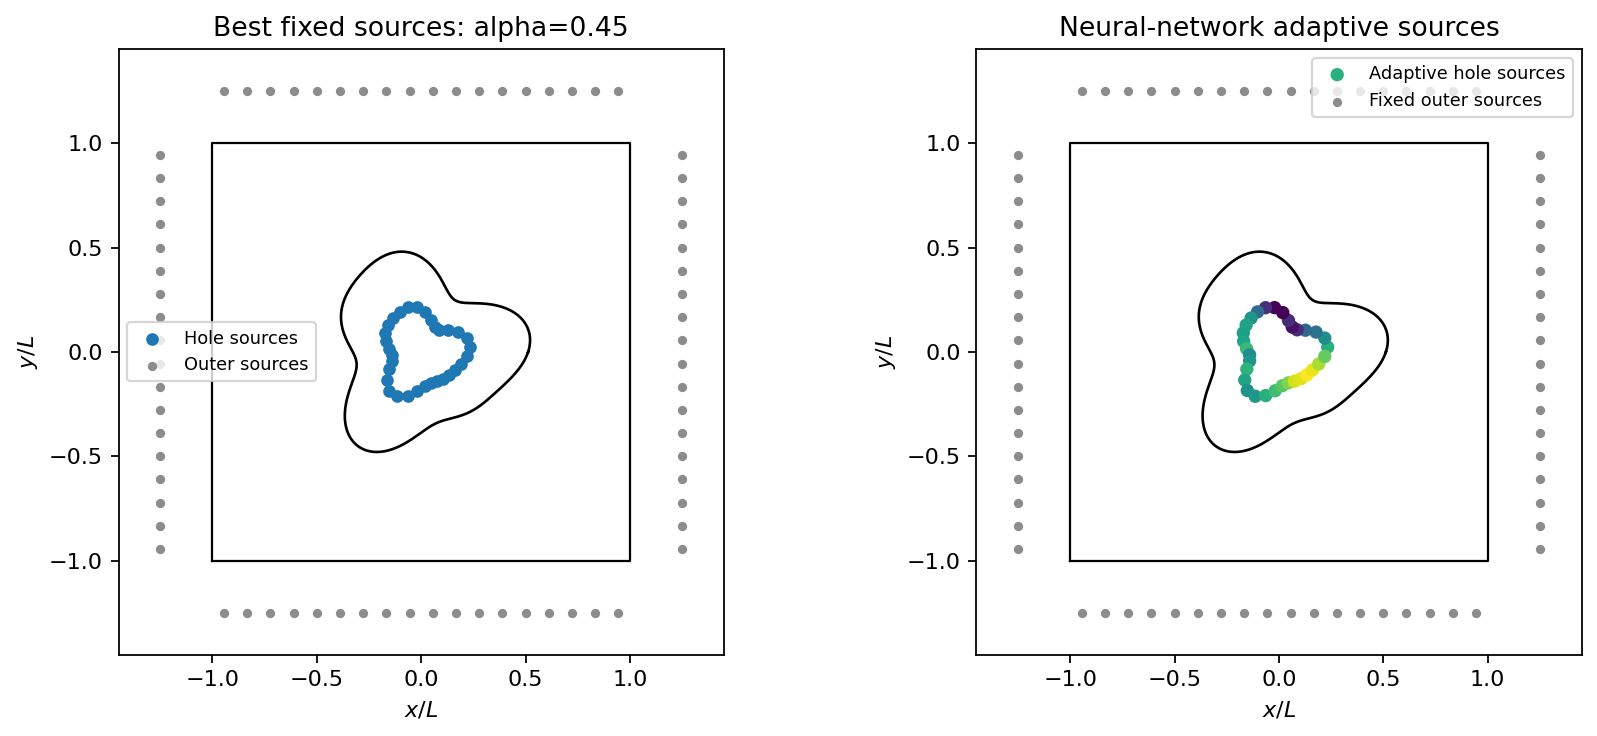

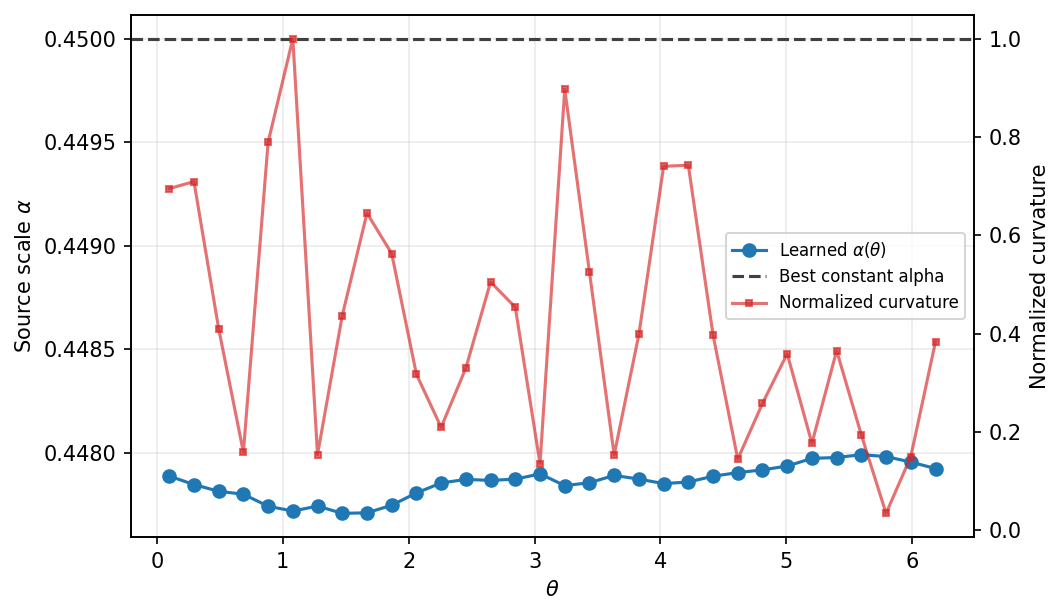

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.7), dpi=160)
for ax in axes:
    ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], "k-", lw=1.0)
    ax.plot(hole_plot[:, 0], hole_plot[:, 1], "k-", lw=1.2)
    ax.set_aspect("equal")
    ax.set_xlim(-1.45, 1.45)
    ax.set_ylim(-1.45, 1.45)
    ax.set_xlabel(r"$x/L$")
    ax.set_ylabel(r"$y/L$")

axes[0].scatter(FIXED_BEST_SOURCES[:N_HOLE_SOURCES, 0], FIXED_BEST_SOURCES[:N_HOLE_SOURCES, 1], s=22, c="#1f77b4", label="Hole sources")
axes[0].scatter(FIXED_BEST_SOURCES[N_HOLE_SOURCES:, 0], FIXED_BEST_SOURCES[N_HOLE_SOURCES:, 1], s=10, c="0.55", label="Outer sources")
axes[0].set_title(f"Best fixed sources: alpha={BEST_FIXED_ALPHA:.2f}")
axes[0].legend(fontsize=8)

axes[1].scatter(ADAPTIVE_SOURCES[:N_HOLE_SOURCES, 0], ADAPTIVE_SOURCES[:N_HOLE_SOURCES, 1], s=25, c=ADAPTIVE_ALPHA, cmap="viridis", label="Adaptive hole sources")
axes[1].scatter(ADAPTIVE_SOURCES[N_HOLE_SOURCES:, 0], ADAPTIVE_SOURCES[N_HOLE_SOURCES:, 1], s=10, c="0.55", label="Fixed outer sources")
axes[1].set_title("Neural-network adaptive sources")
axes[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "source_locations.png", dpi=300, bbox_inches="tight")
plt.show()

_, _, _, source_curvature = hole_geometry(SOURCE_THETA)
curvature_normalized = source_curvature / source_curvature.max()
order = np.argsort(SOURCE_THETA)
fig, ax1 = plt.subplots(figsize=(7.2, 4.2), dpi=150)
ax1.plot(SOURCE_THETA[order], ADAPTIVE_ALPHA[order], "o-", color="#1f77b4", label=r"Learned $\alpha(\theta)$")
ax1.axhline(BEST_FIXED_ALPHA, color="0.25", ls="--", label="Best constant alpha")
ax1.set_xlabel(r"$\theta$")
ax1.set_ylabel(r"Source scale $\alpha$")
ax2 = ax1.twinx()
ax2.plot(SOURCE_THETA[order], curvature_normalized[order], "s-", ms=3, color="#d62728", alpha=0.65, label="Normalized curvature")
ax2.set_ylabel("Normalized curvature")
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], fontsize=8, loc="best")
ax1.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "adaptive_alpha_vs_curvature.png", dpi=300, bbox_inches="tight")
plt.show()



Using COMSOL M3 reference: C:\Users\magic\Desktop\KM-PIKFNN\不规则圆孔\irregular_hole_M3_grid_801.txt

=== Relative L2 errors against COMSOL M3, with M2-M3 reference change ===
Field      FEM23-global   Fixed-global  Adaptive-global    FEM23-near    Fixed-near   Adaptive-near
ux           4.0641e-05     8.0718e-01       8.0595e-01    5.1794e-05    6.9671e-01      6.9562e-01
uy           2.2126e-05     7.5625e-02       7.5545e-02    3.0150e-05    8.3192e-02      8.3152e-02
sxx          1.4282e-02     9.4944e-01       9.4838e-01    1.5268e-02    9.1287e-01      9.1161e-01
syy          2.2078e-03     1.4549e-01       1.4533e-01    3.2607e-03    1.5836e-01      1.5824e-01
sxy          1.1125e-02     7.3714e-01       7.3623e-01    1.1557e-02    7.3442e-01      7.3348e-01
vm           2.1555e-03     1.4734e-01       1.4720e-01    3.1789e-03    1.7187e-01      1.7174e-01


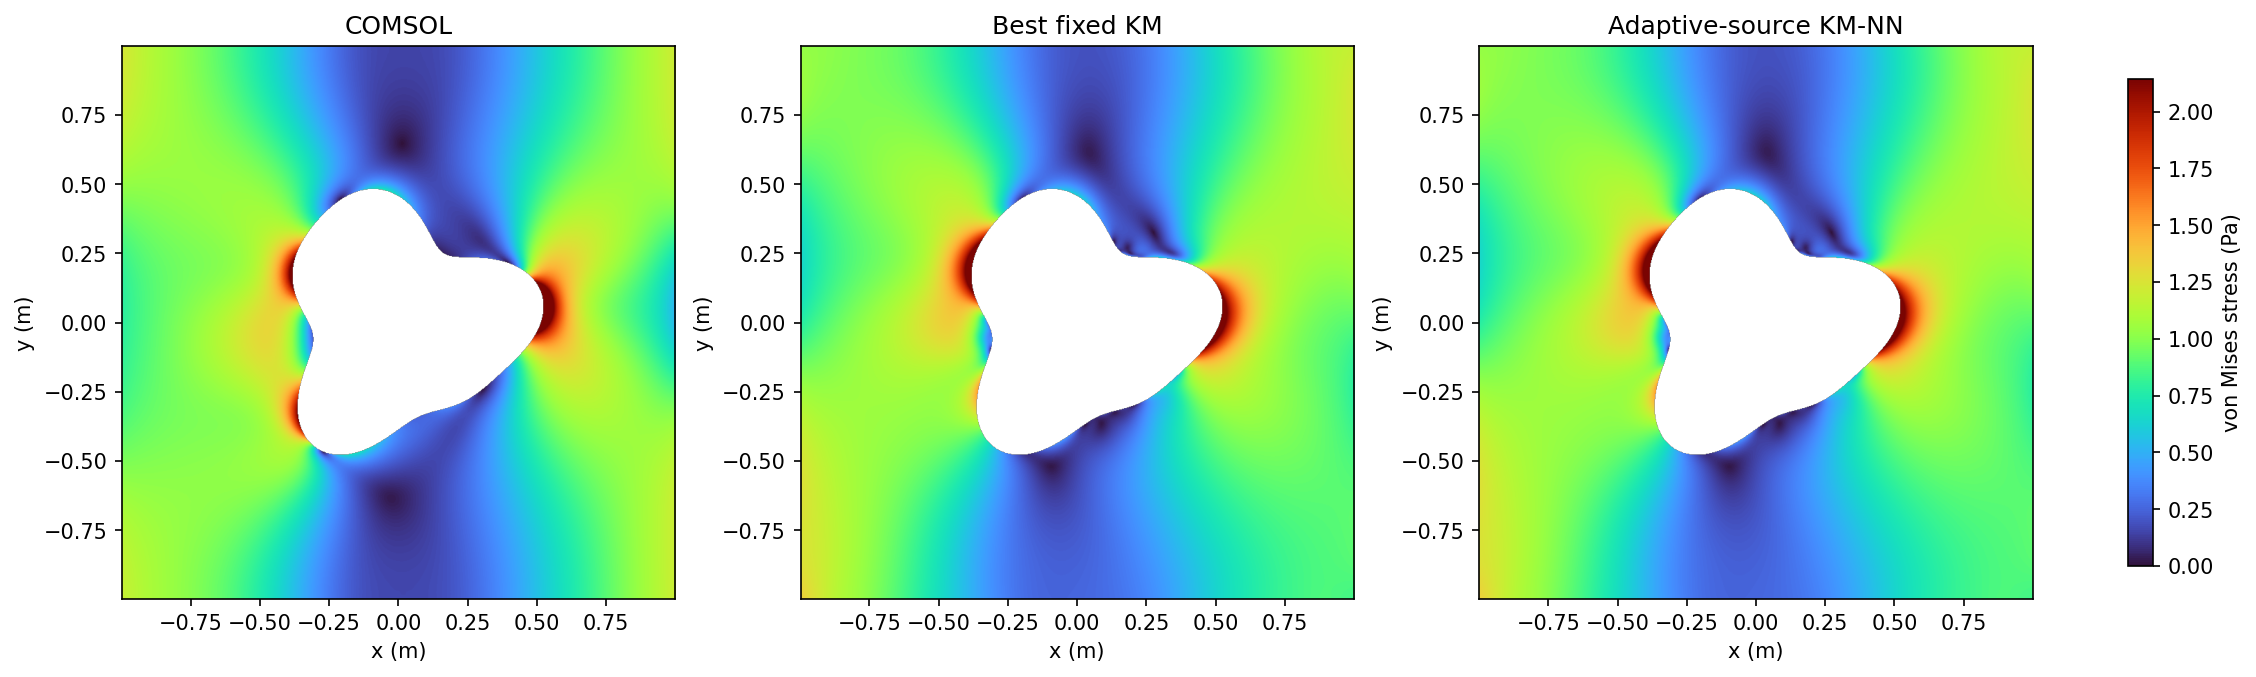

In [8]:
def evaluate_in_chunks(points, sources, coeffs, chunk_size=12000):
    fields = {key: [] for key in ("ux", "uy", "sxx", "syy", "sxy")}
    for start in range(0, len(points), chunk_size):
        chunk = points[start:start + chunk_size]
        values = fields_from_coefficients_np(chunk, sources, coeffs)
        for key, value in zip(fields, values):
            fields[key].append(value)
    return {key: np.concatenate(parts) for key, parts in fields.items()}


def von_mises_plane_stress(sxx, syy, sxy):
    return np.sqrt(np.maximum(sxx**2 - sxx * syy + syy**2 + 3.0 * sxy**2, 0.0))


def relative_l2(prediction, reference):
    denominator = max(np.linalg.norm(reference), 1.0e-15)
    return float(np.linalg.norm(prediction - reference) / denominator)


def error_metrics(pred, ref, mask):
    metrics = {}
    for key in ("ux", "uy", "sxx", "syy", "sxy", "vm"):
        metrics[key] = relative_l2(pred[key][mask], ref[key][mask])
    return metrics


comsol_path = COMSOL_M3_FILE
COMSOL_RESULTS = None
if not comsol_path.is_file():
    raise FileNotFoundError(f"M3 reference file was not found: {comsol_path}")
else:
    print(f"\nUsing COMSOL M3 reference: {comsol_path}")
    if not FEM_MESH_CONVERGED:
        print("WARNING: M2-M3 mesh convergence did not pass every screening criterion.")
    comsol = FEM_M3
    finite = np.isfinite(np.column_stack((
        comsol["ux"], comsol["uy"], comsol["sxx"], comsol["syy"], comsol["sxy"], comsol["vm"]
    ))).all(axis=1)
    points_star = np.column_stack((comsol["x"] / L_REAL, comsol["y"] / L_REAL))
    valid_points = points_star[finite]

    reference = {
        "ux": comsol["ux"][finite] / U0_REAL,
        "uy": comsol["uy"][finite] / U0_REAL,
        "sxx": comsol["sxx"][finite] / SIGMA_SCALE,
        "syy": comsol["syy"][finite] / SIGMA_SCALE,
        "sxy": comsol["sxy"][finite] / SIGMA_SCALE,
        "vm": comsol["vm"][finite] / SIGMA_SCALE,
    }
    fixed_prediction = evaluate_in_chunks(valid_points, FIXED_BEST_SOURCES, FIXED_BEST_COEFFS)
    adaptive_prediction = evaluate_in_chunks(valid_points, ADAPTIVE_SOURCES, ADAPTIVE_COEFFS)
    fixed_prediction["vm"] = von_mises_plane_stress(fixed_prediction["sxx"], fixed_prediction["syy"], fixed_prediction["sxy"])
    adaptive_prediction["vm"] = von_mises_plane_stress(adaptive_prediction["sxx"], adaptive_prediction["syy"], adaptive_prediction["sxy"])

    # Align the arbitrary horizontal rigid translation before comparing ux.
    fixed_shift = np.mean(fixed_prediction["ux"] - reference["ux"])
    adaptive_shift = np.mean(adaptive_prediction["ux"] - reference["ux"])
    fixed_prediction["ux"] -= fixed_shift
    adaptive_prediction["ux"] -= adaptive_shift

    all_mask = np.ones(len(valid_points), dtype=bool)
    radial_distance = np.linalg.norm(valid_points, axis=1)
    near_hole_mask = radial_distance <= NEAR_HOLE_RADIUS
    fixed_global = error_metrics(fixed_prediction, reference, all_mask)
    adaptive_global = error_metrics(adaptive_prediction, reference, all_mask)
    fixed_near = error_metrics(fixed_prediction, reference, near_hole_mask)
    adaptive_near = error_metrics(adaptive_prediction, reference, near_hole_mask)

    print("\n=== Relative L2 errors against COMSOL M3, with M2-M3 reference change ===")
    print(
        f"{'Field':<9}{'FEM23-global':>14}{'Fixed-global':>15}{'Adaptive-global':>17}"
        f"{'FEM23-near':>14}{'Fixed-near':>14}{'Adaptive-near':>16}"
    )
    for key in ("ux", "uy", "sxx", "syy", "sxy", "vm"):
        print(
            f"{key:<9}{FEM_CONV_M2_M3['global'][key]:>14.4e}"
            f"{fixed_global[key]:>15.4e}{adaptive_global[key]:>17.4e}"
            f"{FEM_CONV_M2_M3['near_hole'][key]:>14.4e}"
            f"{fixed_near[key]:>14.4e}{adaptive_near[key]:>16.4e}"
        )

    summary_path = OUTPUT_DIR / "comsol_error_summary.csv"
    with summary_path.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow([
            "field", "fem_m2_m3_global", "fixed_global", "adaptive_global",
            "fem_m2_m3_near_hole", "fixed_near_hole", "adaptive_near_hole",
        ])
        for key in ("ux", "uy", "sxx", "syy", "sxy", "vm"):
            writer.writerow([
                key,
                FEM_CONV_M2_M3["global"][key], fixed_global[key], adaptive_global[key],
                FEM_CONV_M2_M3["near_hole"][key], fixed_near[key], adaptive_near[key],
            ])

    COMSOL_RESULTS = {
        "path": str(comsol_path),
        "finite_mask": finite,
        "points_star": points_star,
        "reference": reference,
        "fixed": fixed_prediction,
        "adaptive": adaptive_prediction,
        "fixed_global": fixed_global,
        "adaptive_global": adaptive_global,
        "fixed_near": fixed_near,
        "adaptive_near": adaptive_near,
        "fem_convergence_m1_m2": FEM_CONV_M1_M2,
        "fem_convergence_m2_m3": FEM_CONV_M2_M3,
        "fem_mesh_converged": FEM_MESH_CONVERGED,
    }

    # Common-scale von Mises comparison on the exported regular grid.
    x_all, y_all = comsol["x"], comsol["y"]
    x_unique, y_unique = np.unique(x_all), np.unique(y_all)
    shape = (len(y_unique), len(x_unique))
    def grid_map(valid_values):
        full = np.full(len(x_all), np.nan)
        full[finite] = valid_values
        ix = np.searchsorted(x_unique, x_all)
        iy = np.searchsorted(y_unique, y_all)
        image = np.full(shape, np.nan)
        image[iy, ix] = full
        return image

    vm_ref_map = grid_map(reference["vm"] * SIGMA_SCALE)
    vm_fixed_map = grid_map(fixed_prediction["vm"] * SIGMA_SCALE)
    vm_adapt_map = grid_map(adaptive_prediction["vm"] * SIGMA_SCALE)
    vmax = np.nanpercentile(vm_ref_map, 99.8)
    fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.4), dpi=150, constrained_layout=True)
    for ax, image_data, title in zip(
        axes,
        (vm_ref_map, vm_fixed_map, vm_adapt_map),
        ("COMSOL", "Best fixed KM", "Adaptive-source KM-NN"),
    ):
        im = ax.imshow(image_data, origin="lower", extent=[x_unique.min(), x_unique.max(), y_unique.min(), y_unique.max()], cmap="turbo", vmin=0.0, vmax=vmax)
        ax.set_aspect("equal")
        ax.set_title(title)
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
    fig.colorbar(im, ax=axes, label="von Mises stress (Pa)", shrink=0.88)
    fig.savefig(OUTPUT_DIR / "comsol_fixed_adaptive_vm.png", dpi=300, bbox_inches="tight")
    plt.show()


In [ ]:
history_array = np.asarray(training_history, dtype=float)
scan_array = np.column_stack((scan_alpha, scan_val, scan_cond))
save_items = {
    "source_theta": SOURCE_THETA,
    "fixed_default_sources": FIXED_DEFAULT_SOURCES,
    "fixed_default_coeffs": FIXED_DEFAULT_COEFFS,
    "fixed_best_alpha": np.asarray(BEST_FIXED_ALPHA),
    "fixed_best_sources": FIXED_BEST_SOURCES,
    "fixed_best_coeffs": FIXED_BEST_COEFFS,
    "adaptive_alpha": ADAPTIVE_ALPHA,
    "adaptive_sources": ADAPTIVE_SOURCES,
    "adaptive_coeffs": ADAPTIVE_COEFFS,
    "fixed_alpha_scan": scan_array,
    "training_history": history_array,
    "fixed_dense_test_loss": np.asarray(fixed_test_loss),
    "adaptive_dense_test_loss": np.asarray(adaptive_test_loss),
}
np.savez_compressed(OUTPUT_DIR / "irregular_hole_adaptive_km_results.npz", **save_items)
print(f"\nSaved results to: {OUTPUT_DIR.resolve()}")



Saved results to: C:\Users\magic\Desktop\KM-PIKFNN\不规则圆孔\irregular_hole_km_outputs


: 